# 03 - فلاتر وتحسين الصور

يجمع هذا الدفتر تقنيات تحسين الإضاءة والتباين والتحويلات النقطية من LAB5، وتقنيات Histogram وSmoothing Filters من LAB6. يتيح رفع صورة أو عدة صور، والمقارنة التفاعلية، والحفظ في Google Drive.

## أهداف الدفتر

- رفع صورة أو عدة صور من الجهاز.
- تحسين السطوع والتباين.
- تطبيق Log وGamma Transformation.
- عرض Histogram قبل التحسين وبعده.
- تطبيق Histogram Equalization على الصورة الرمادية.
- مقارنة Average وGaussian وMedian وBilateral.
- استخدام filter2D وSharpening Kernel.
- تغيير القيم تفاعليًا ثم حفظ النتائج.

## 1. استيراد المكتبات وربط Google Drive

In [32]:
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
    PROJECT_ROOT = Path(
        '/content/drive/MyDrive/'
        'VisionStudio_Android_ImageProcessing'
    )
except ImportError:
    IN_COLAB = False
    PROJECT_ROOT = Path('VisionStudio_Android_ImageProcessing')

INPUT_DIR = PROJECT_ROOT / '02_Data/Images/Input'
OUTPUT_DIR = (
    PROJECT_ROOT
    / '04_Outputs/Images/03_Filters_Enhancement'
)

INPUT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print('Running in Colab:', IN_COLAB)
print('Input directory:', INPUT_DIR)
print('Output directory:', OUTPUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Running in Colab: True
Input directory: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/02_Data/Images/Input
Output directory: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/04_Outputs/Images/03_Filters_Enhancement


## 2. دوال العرض والتحقق

يجب أن يكون حجم Kernel عددًا فرديًا مثل 3 أو 5 أو 7، لأن الفلتر يحتاج بكسلًا مركزيًا.

In [33]:
def to_rgb(image):
    if image.ndim == 2:
        return image
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


def show_comparison(results, columns=3, figure_width=16):
    items = list(results.items())
    rows = int(np.ceil(len(items) / columns))
    fig, axes = plt.subplots(
        rows, columns,
        figsize=(figure_width, rows * 4.5),
        squeeze=False
    )

    for axis, (title, result) in zip(axes.ravel(), items):
        axis.imshow(
            to_rgb(result),
            cmap='gray' if result.ndim == 2 else None
        )
        axis.set_title(title)
        axis.axis('off')

    for axis in axes.ravel()[len(items):]:
        axis.axis('off')

    plt.tight_layout()
    plt.show()


def valid_kernel_size(kernel_size):
    kernel_size = int(kernel_size)
    if kernel_size < 1:
        kernel_size = 1
    if kernel_size % 2 == 0:
        kernel_size += 1
    return kernel_size

## 3. دوال تحسين الصورة والفلاتر

In [34]:
def adjust_brightness_contrast(image, brightness=0, contrast=1.0):
    result = image.astype(np.float32) * float(contrast) + float(brightness)
    return np.clip(result, 0, 255).astype(np.uint8)


def gamma_correction(image, gamma=1.0):
    if gamma <= 0:
        raise ValueError('Gamma must be greater than zero.')
    normalized = image.astype(np.float32) / 255.0
    corrected = np.power(normalized, gamma)
    return np.clip(corrected * 255, 0, 255).astype(np.uint8)


def log_transform(image):
    float_image = image.astype(np.float32)
    maximum = float(np.max(float_image))
    if maximum == 0:
        return image.copy()
    constant = 255.0 / np.log1p(maximum)
    result = constant * np.log1p(float_image)
    return np.clip(result, 0, 255).astype(np.uint8)


def equalize_grayscale(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    return gray, cv2.equalizeHist(gray)


def equalize_color_luminance(image):
    ycrcb = cv2.cvtColor(image, cv2.COLOR_BGR2YCrCb)
    ycrcb[:, :, 0] = cv2.equalizeHist(ycrcb[:, :, 0])
    return cv2.cvtColor(ycrcb, cv2.COLOR_YCrCb2BGR)


def average_filter(image, kernel_size=5):
    k = valid_kernel_size(kernel_size)
    return cv2.blur(image, (k, k))


def gaussian_filter(image, kernel_size=5, sigma=0):
    k = valid_kernel_size(kernel_size)
    return cv2.GaussianBlur(image, (k, k), sigma)


def median_filter(image, kernel_size=5):
    k = max(3, valid_kernel_size(kernel_size))
    return cv2.medianBlur(image, k)


def bilateral_filter(image, diameter=9, sigma_color=75, sigma_space=75):
    return cv2.bilateralFilter(
        image, int(diameter), float(sigma_color), float(sigma_space)
    )


def custom_filter2d(image, kernel_size=5):
    k = valid_kernel_size(kernel_size)
    kernel = np.ones((k, k), dtype=np.float32) / (k * k)
    return cv2.filter2D(image, ddepth=-1, kernel=kernel)


def sharpen_image(image):
    kernel = np.array([
        [0, -1, 0],
        [-1, 5, -1],
        [0, -1, 0]
    ], dtype=np.float32)
    return cv2.filter2D(image, ddepth=-1, kernel=kernel)

## 4. رفع صورة أو عدة صور

يمكن اختيار أكثر من صورة. تُحفظ الصور الأصلية داخل مجلد الإدخال قبل المعالجة.

In [35]:
# ============================================================
# قراءة الصور من Google Drive
# مع إمكانية رفع صور جديدة عند الحاجة فقط
# ============================================================

# اجعلها True فقط عندما تريد إضافة صور جديدة
UPLOAD_NEW_FILES = False

# صيغ الصور المدعومة
SUPPORTED_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}

# سيحتوي هذا القاموس على جميع الصور
uploaded_images = {}


# ============================================================
# 1. قراءة الصور الموجودة مسبقًا داخل مجلد Input
# ============================================================

existing_image_paths = sorted([
    path
    for path in INPUT_DIR.iterdir()
    if (
        path.is_file()
        and path.suffix.lower()
        in SUPPORTED_EXTENSIONS
    )
])

for image_path in existing_image_paths:

    loaded_image = cv2.imread(
        str(image_path),
        cv2.IMREAD_COLOR
    )

    if loaded_image is None:
        print(
            f"تعذر قراءة الصورة: "
            f"{image_path.name}"
        )
        continue

    uploaded_images[
        image_path.name
    ] = loaded_image


print(
    "عدد الصور الموجودة مسبقًا في Drive:",
    len(uploaded_images)
)


# ============================================================
# 2. رفع صور جديدة عند الحاجة
# ============================================================

if IN_COLAB and UPLOAD_NEW_FILES:

    from google.colab import files

    print(
        "اختر صورة أو عدة صور من جهازك:"
    )

    uploaded_files = files.upload()

    for file_name, file_data in uploaded_files.items():

        # تحويل بيانات الصورة إلى مصفوفة NumPy
        image_array = np.frombuffer(
            file_data,
            dtype=np.uint8
        )

        # فك ترميز الصورة باستخدام OpenCV
        loaded_image = cv2.imdecode(
            image_array,
            cv2.IMREAD_COLOR
        )

        if loaded_image is None:
            print(
                f"تعذر قراءة الملف: "
                f"{file_name}"
            )
            continue

        # الحصول على اسم الملف فقط
        safe_file_name = Path(
            file_name
        ).name

        # مكان حفظ الصورة داخل Google Drive
        input_path = (
            INPUT_DIR / safe_file_name
        )

        # حفظ الصورة حتى لا تحتاج إلى رفعها مرة أخرى
        save_success = cv2.imwrite(
            str(input_path),
            loaded_image
        )

        if not save_success:
            print(
                f"فشل حفظ الصورة: "
                f"{safe_file_name}"
            )
            continue

        # إضافة الصورة إلى قاموس الصور
        uploaded_images[
            safe_file_name
        ] = loaded_image

        print(
            f"تمت إضافة وحفظ الصورة: "
            f"{safe_file_name}"
        )


# ============================================================
# 3. التأكد من وجود صورة واحدة على الأقل
# ============================================================

if not uploaded_images:

    raise ValueError(
        "لا توجد صور داخل مجلد Input.\n"
        "ضع صورة داخل المجلد:\n"
        f"{INPUT_DIR}\n"
        "أو اجعل:\n"
        "UPLOAD_NEW_FILES = True"
    )


# ============================================================
# 4. عرض الصور الجاهزة للمعالجة
# ============================================================

print(
    f"\nعدد الصور الجاهزة للمعالجة: "
    f"{len(uploaded_images)}"
)

for index, (
    file_name,
    loaded_image
) in enumerate(
    uploaded_images.items(),
    start=1
):

    print(
        f"{index}. {file_name} "
        f"- الأبعاد: {loaded_image.shape}"
    )

عدد الصور الموجودة مسبقًا في Drive: 4

عدد الصور الجاهزة للمعالجة: 4
1. R.jpeg - الأبعاد: (736, 736, 3)
2. balloons.jpg - الأبعاد: (547, 602, 3)
3. children.jpeg - الأبعاد: (774, 1376, 3)
4. coins.jpg - الأبعاد: (390, 400, 3)


## 5. اختيار صورة المقارنة

تُستخدم أول صورة في العروض التفاعلية، ثم تُعالج جميع الصور في قسم الحفظ النهائي.

Selected image: R.jpeg
Shape: (736, 736, 3)
Data type: uint8


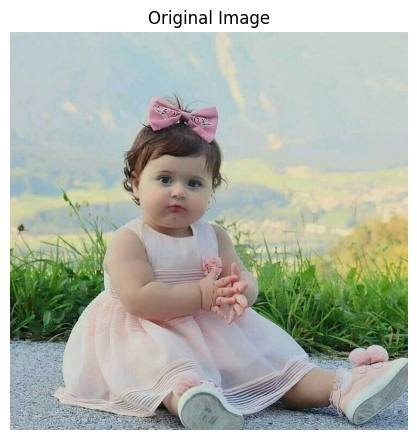

In [25]:
selected_name = next(iter(uploaded_images))
image = uploaded_images[selected_name]

print('Selected image:', selected_name)
print('Shape:', image.shape)
print('Data type:', image.dtype)
show_comparison({'Original Image': image}, columns=1, figure_width=8)

## 6. السطوع والتباين وLog وGamma Transformation

- السطوع يضيف قيمة إلى البكسلات.
- التباين يوسّع أو يضيّق الفرق بين القيم.
- Log Transformation يبرز التفاصيل الداكنة.
- Gamma أقل من 1 يفتح الصورة، وأكبر من 1 يجعلها أغمق وفق الصيغة المستخدمة هنا.

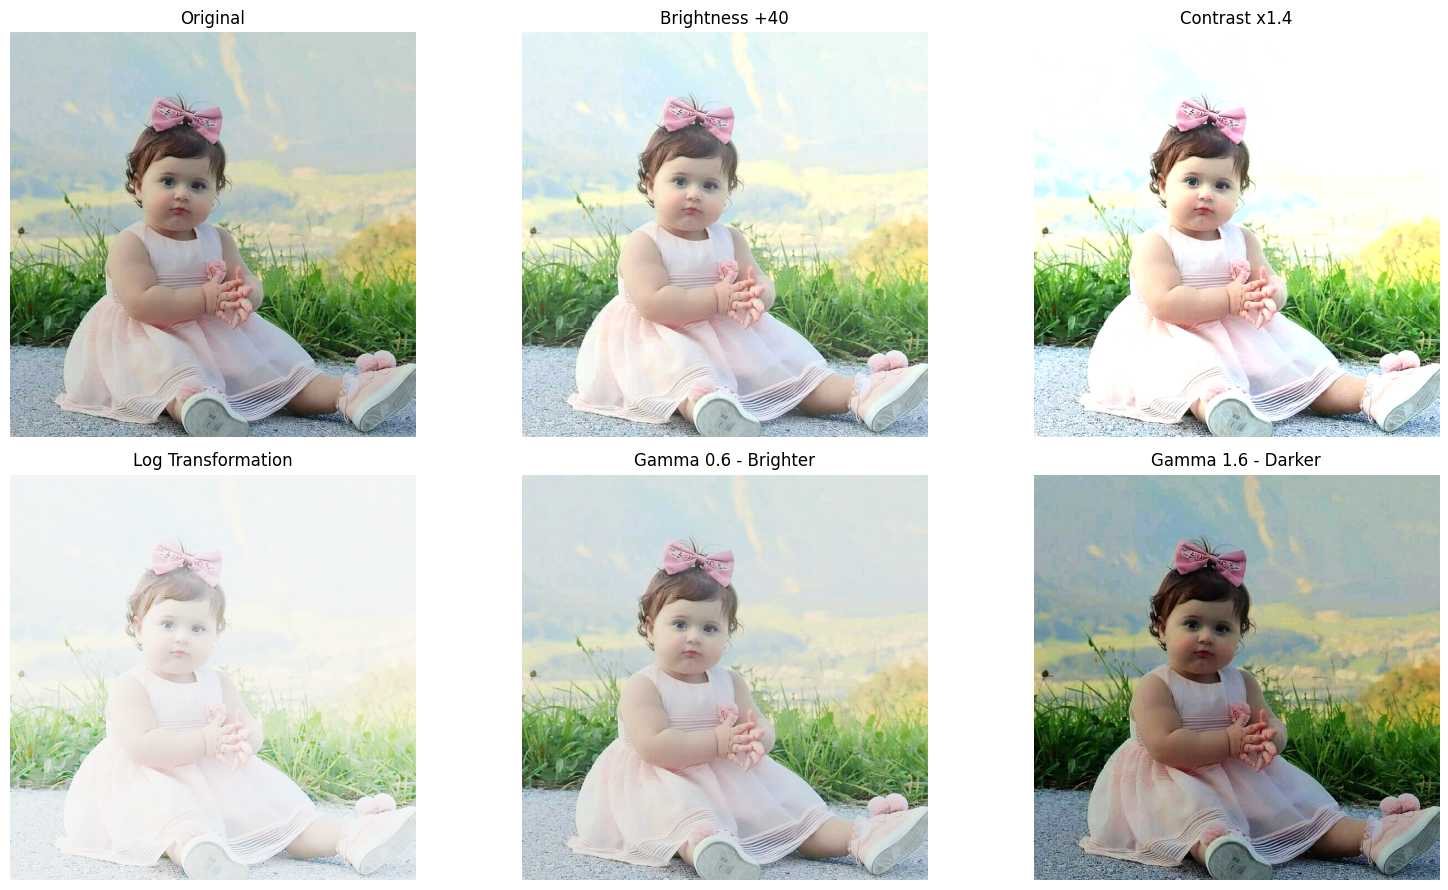

In [26]:
brighter = adjust_brightness_contrast(image, brightness=40, contrast=1.0)
higher_contrast = adjust_brightness_contrast(
    image, brightness=0, contrast=1.4
)
log_result = log_transform(image)
gamma_bright = gamma_correction(image, gamma=0.6)
gamma_dark = gamma_correction(image, gamma=1.6)

show_comparison(
    {
        'Original': image,
        'Brightness +40': brighter,
        'Contrast x1.4': higher_contrast,
        'Log Transformation': log_result,
        'Gamma 0.6 - Brighter': gamma_bright,
        'Gamma 1.6 - Darker': gamma_dark
    },
    columns=3
)

## 7. Histogram Equalization

نقارن توزيع شدة الإضاءة قبل Equalization وبعده. كما نطبّق التحسين على قناة الإضاءة في الصورة الملونة حتى لا تتشوّه الألوان.

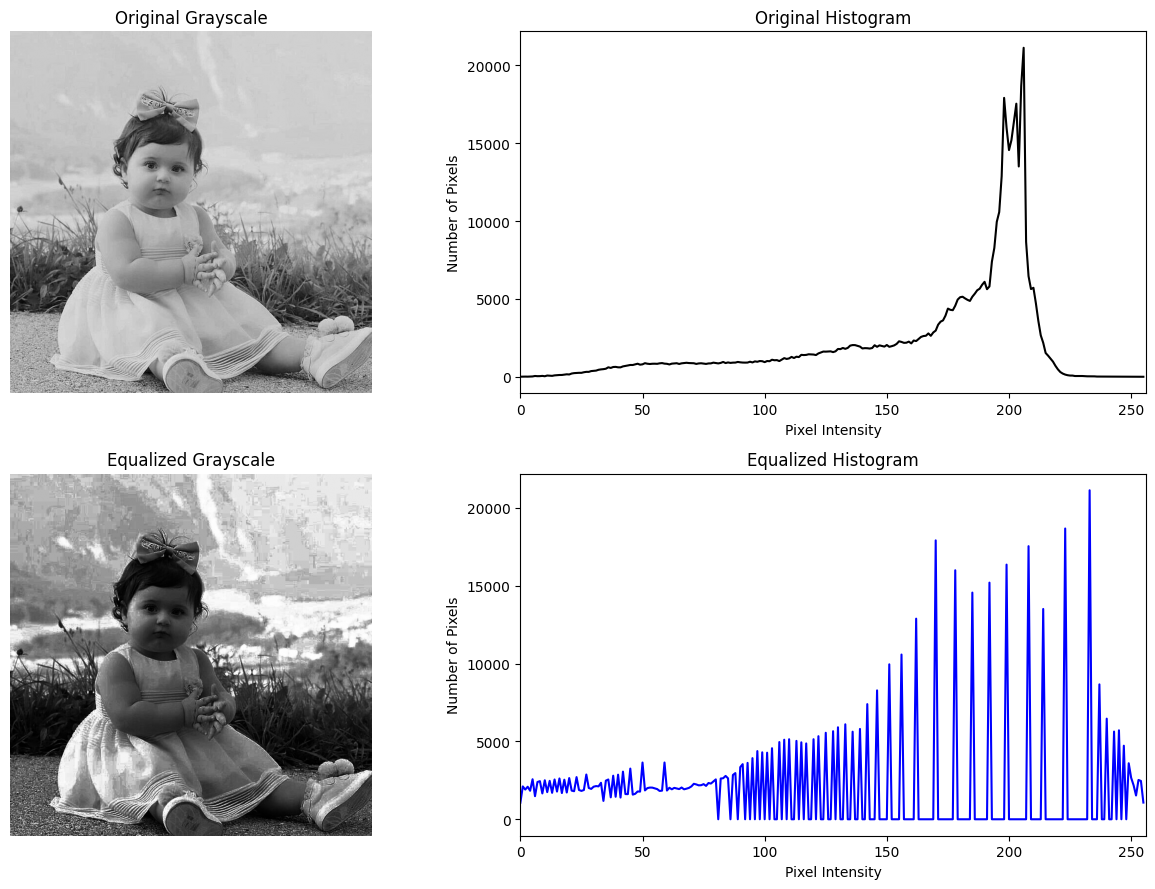

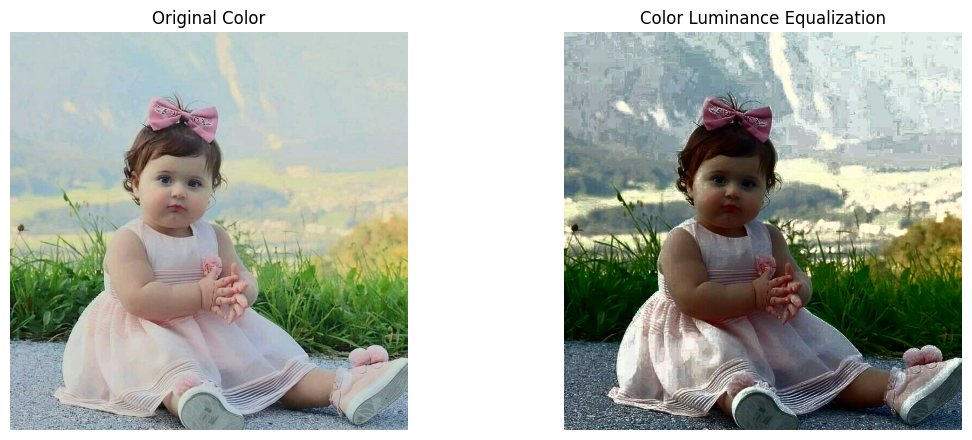

In [27]:
gray, equalized_gray = equalize_grayscale(image)
equalized_color = equalize_color_luminance(image)

hist_original = cv2.calcHist([gray], [0], None, [256], [0, 256])
hist_equalized = cv2.calcHist(
    [equalized_gray], [0], None, [256], [0, 256]
)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes[0, 0].imshow(gray, cmap='gray')
axes[0, 0].set_title('Original Grayscale')
axes[0, 0].axis('off')
axes[0, 1].plot(hist_original, color='black')
axes[0, 1].set_title('Original Histogram')
axes[0, 1].set_xlim([0, 256])
axes[0, 1].set_xlabel('Pixel Intensity')
axes[0, 1].set_ylabel('Number of Pixels')
axes[1, 0].imshow(equalized_gray, cmap='gray')
axes[1, 0].set_title('Equalized Grayscale')
axes[1, 0].axis('off')
axes[1, 1].plot(hist_equalized, color='blue')
axes[1, 1].set_title('Equalized Histogram')
axes[1, 1].set_xlim([0, 256])
axes[1, 1].set_xlabel('Pixel Intensity')
axes[1, 1].set_ylabel('Number of Pixels')
plt.tight_layout()
plt.show()

show_comparison(
    {
        'Original Color': image,
        'Color Luminance Equalization': equalized_color
    },
    columns=2,
    figure_width=12
)

## 8. مقارنة فلاتر التنعيم والحدة

- Average سريع لكنه يطمس الحواف.
- Gaussian يعطي تنعيمًا طبيعيًا.
- Median مناسب لضوضاء Salt-and-Pepper.
- Bilateral يقلل الضوضاء مع المحافظة على الحواف بصورة أفضل.

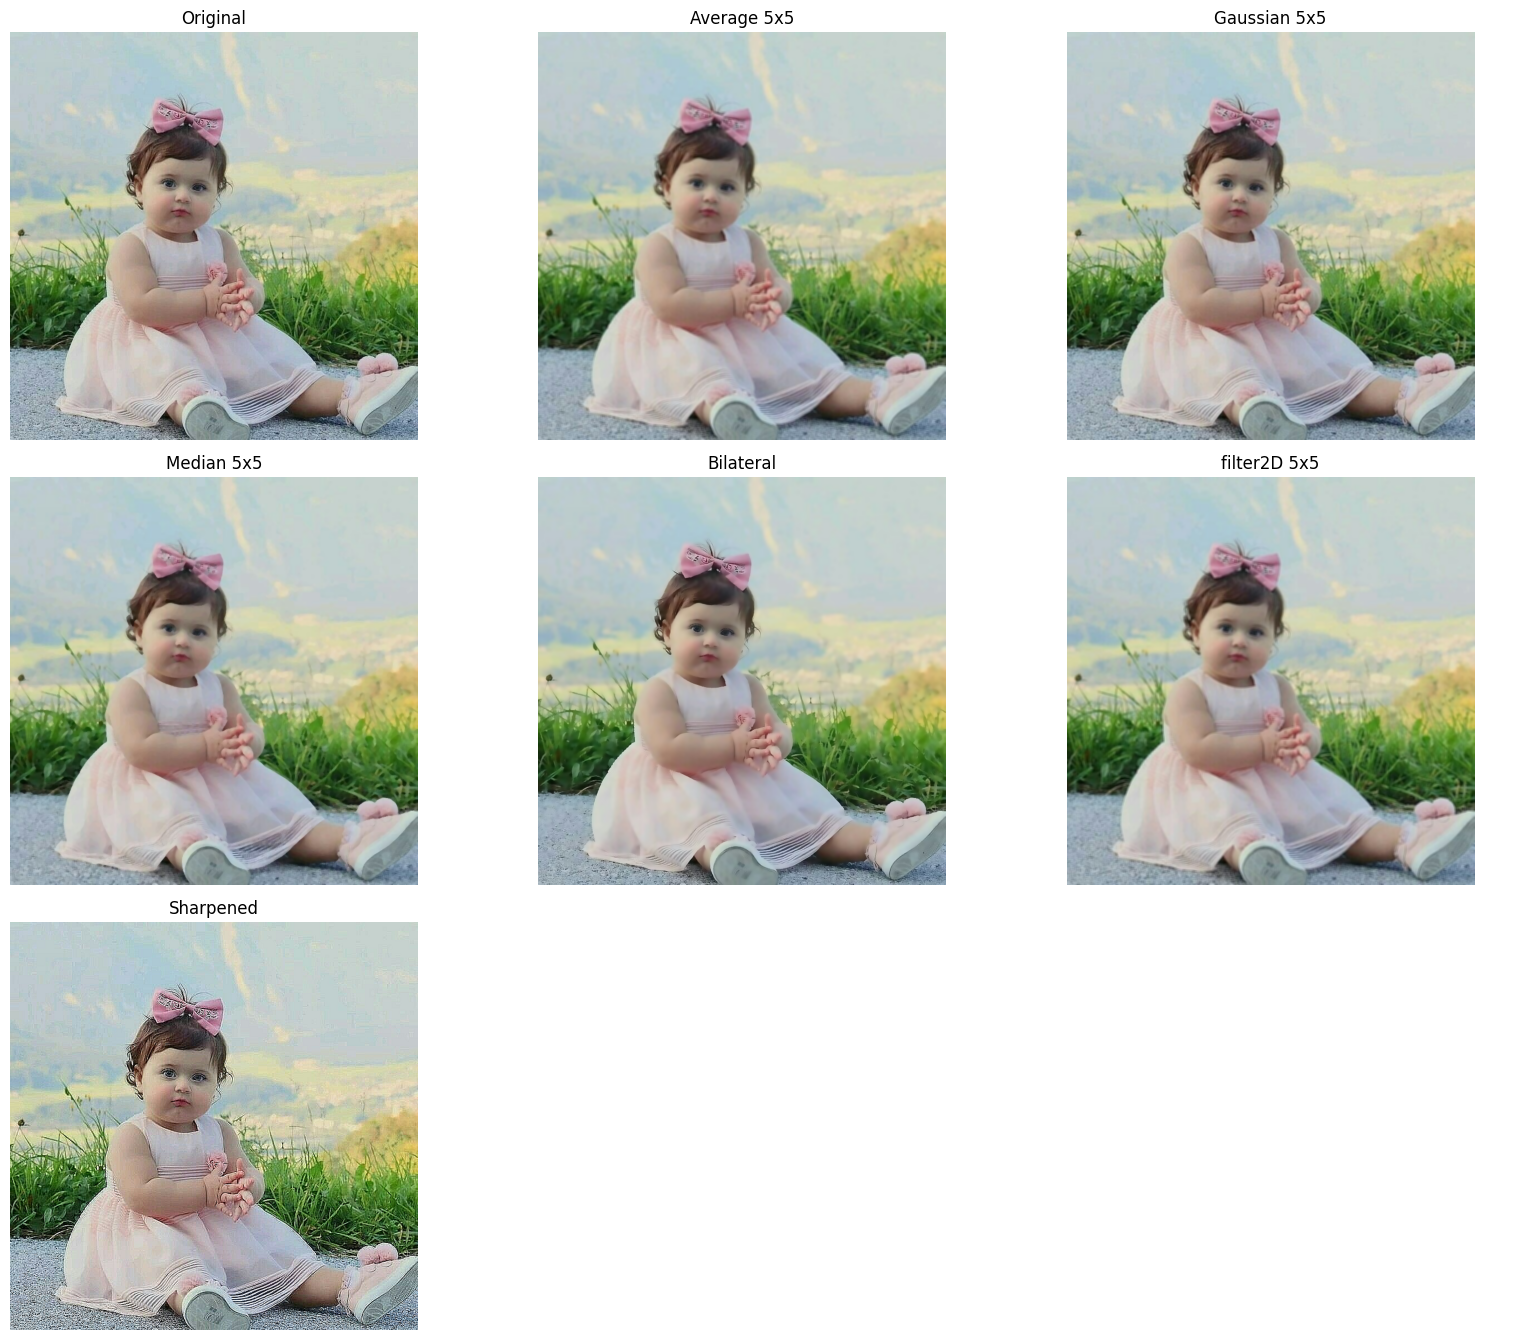

In [28]:
average_result = average_filter(image, 5)
gaussian_result = gaussian_filter(image, 5)
median_result = median_filter(image, 5)
bilateral_result = bilateral_filter(image, 9, 75, 75)
filter2d_result = custom_filter2d(image, 5)
sharpened_result = sharpen_image(image)

show_comparison(
    {
        'Original': image,
        'Average 5x5': average_result,
        'Gaussian 5x5': gaussian_result,
        'Median 5x5': median_result,
        'Bilateral': bilateral_result,
        'filter2D 5x5': filter2d_result,
        'Sharpened': sharpened_result
    },
    columns=3
)

## 9. أداة تفاعلية لمقارنة الفلاتر

اختر الفلتر وغيّر Kernel Size. عند اختيار Bilateral تُستخدم قيم Sigma أيضًا.

In [29]:
try:
    import ipywidgets as widgets
    from IPython.display import display
    WIDGETS_AVAILABLE = True
except ImportError:
    WIDGETS_AVAILABLE = False
    print('الأدوات التفاعلية متاحة تلقائيًا داخل Google Colab.')


def interactive_filter(
    filter_name='Gaussian', kernel_size=5, sigma=0.0,
    sigma_color=75, sigma_space=75
):
    k = valid_kernel_size(kernel_size)

    if filter_name == 'Average':
        result = average_filter(image, k)
    elif filter_name == 'Gaussian':
        result = gaussian_filter(image, k, sigma)
    elif filter_name == 'Median':
        result = median_filter(image, k)
    elif filter_name == 'Bilateral':
        result = bilateral_filter(
            image, k, sigma_color, sigma_space
        )
    elif filter_name == 'filter2D':
        result = custom_filter2d(image, k)
    else:
        result = sharpen_image(image)

    show_comparison(
        {
            'Original': image,
            f'{filter_name} - Kernel {k}': result
        },
        columns=2,
        figure_width=12
    )


if WIDGETS_AVAILABLE:
    filter_controls = widgets.interactive(
        interactive_filter,
        filter_name=widgets.Dropdown(
            options=[
                'Average', 'Gaussian', 'Median',
                'Bilateral', 'filter2D', 'Sharpen'
            ],
            value='Gaussian',
            description='Filter'
        ),
        kernel_size=widgets.IntSlider(
            value=5, min=1, max=15, step=2, description='Kernel'
        ),
        sigma=widgets.FloatSlider(
            value=0.0, min=0.0, max=10.0, step=0.5, description='Sigma'
        ),
        sigma_color=widgets.IntSlider(
            value=75, min=10, max=200, step=5, description='Color'
        ),
        sigma_space=widgets.IntSlider(
            value=75, min=10, max=200, step=5, description='Space'
        )
    )
    display(filter_controls)

interactive(children=(Dropdown(description='Filter', index=1, options=('Average', 'Gaussian', 'Median', 'Bilat…

## 10. أداة تفاعلية للسطوع والتباين وGamma

In [30]:
def interactive_enhancement(brightness=0, contrast=1.0, gamma=1.0):
    adjusted = adjust_brightness_contrast(
        image, brightness=brightness, contrast=contrast
    )
    result = gamma_correction(adjusted, gamma=gamma)

    show_comparison(
        {
            'Original': image,
            (
                f'Brightness={brightness}, Contrast={contrast:.2f}, '
                f'Gamma={gamma:.2f}'
            ): result
        },
        columns=2,
        figure_width=12
    )


if WIDGETS_AVAILABLE:
    enhancement_controls = widgets.interactive(
        interactive_enhancement,
        brightness=widgets.IntSlider(
            value=0, min=-100, max=100, step=5,
            description='Brightness'
        ),
        contrast=widgets.FloatSlider(
            value=1.0, min=0.2, max=3.0, step=0.1,
            description='Contrast'
        ),
        gamma=widgets.FloatSlider(
            value=1.0, min=0.2, max=3.0, step=0.1,
            description='Gamma'
        )
    )
    display(enhancement_controls)
else:
    print('شغّل الخلية داخل Colab لعرض أدوات التحسين التفاعلية.')

interactive(children=(IntSlider(value=0, description='Brightness', min=-100, step=5), FloatSlider(value=1.0, d…

## 11. معالجة جميع الصور وحفظ النتائج

ينشئ الدفتر مجلدًا مستقلًا لكل صورة، ويحفظ الصور المعالجة ورسم Histogram.

In [31]:
saved_files = []

for file_name, source_image in uploaded_images.items():
    stem = Path(file_name).stem
    image_output_dir = OUTPUT_DIR / stem
    image_output_dir.mkdir(parents=True, exist_ok=True)

    source_gray, source_equalized = equalize_grayscale(source_image)
    results = {
        '00_original.png': source_image,
        '01_grayscale.png': source_gray,
        '02_histogram_equalized_gray.png': source_equalized,
        '03_histogram_equalized_color.png': (
            equalize_color_luminance(source_image)
        ),
        '04_brightness_plus_40.png': adjust_brightness_contrast(
            source_image, brightness=40
        ),
        '05_contrast_1_4.png': adjust_brightness_contrast(
            source_image, contrast=1.4
        ),
        '06_log_transformation.png': log_transform(source_image),
        '07_gamma_0_6.png': gamma_correction(source_image, 0.6),
        '08_average_5x5.png': average_filter(source_image, 5),
        '09_gaussian_5x5.png': gaussian_filter(source_image, 5),
        '10_median_5x5.png': median_filter(source_image, 5),
        '11_bilateral.png': bilateral_filter(source_image, 9, 75, 75),
        '12_filter2d_5x5.png': custom_filter2d(source_image, 5),
        '13_sharpened.png': sharpen_image(source_image)
    }

    for output_name, result_image in results.items():
        output_path = image_output_dir / output_name
        if not cv2.imwrite(str(output_path), result_image):
            raise IOError(f'فشل حفظ الصورة: {output_path}')
        saved_files.append(output_path)

    original_hist = cv2.calcHist(
        [source_gray], [0], None, [256], [0, 256]
    )
    equalized_hist = cv2.calcHist(
        [source_equalized], [0], None, [256], [0, 256]
    )
    histogram_figure, histogram_axis = plt.subplots(figsize=(9, 5))
    histogram_axis.plot(original_hist, label='Original', color='black')
    histogram_axis.plot(equalized_hist, label='Equalized', color='blue')
    histogram_axis.set_title(f'Histogram Comparison - {file_name}')
    histogram_axis.set_xlabel('Pixel Intensity')
    histogram_axis.set_ylabel('Number of Pixels')
    histogram_axis.set_xlim([0, 256])
    histogram_axis.legend()
    histogram_axis.grid(alpha=0.2)
    histogram_figure.tight_layout()
    histogram_path = image_output_dir / '14_histogram_comparison.png'
    histogram_figure.savefig(histogram_path, dpi=150)
    plt.close(histogram_figure)
    saved_files.append(histogram_path)

print(f'تم حفظ {len(saved_files)} ملفًا بنجاح.')
print('مجلد النتائج:', OUTPUT_DIR)
for path in saved_files:
    print('-', path.name)

تم حفظ 60 ملفًا بنجاح.
مجلد النتائج: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/04_Outputs/Images/03_Filters_Enhancement
- 00_original.png
- 01_grayscale.png
- 02_histogram_equalized_gray.png
- 03_histogram_equalized_color.png
- 04_brightness_plus_40.png
- 05_contrast_1_4.png
- 06_log_transformation.png
- 07_gamma_0_6.png
- 08_average_5x5.png
- 09_gaussian_5x5.png
- 10_median_5x5.png
- 11_bilateral.png
- 12_filter2d_5x5.png
- 13_sharpened.png
- 14_histogram_comparison.png
- 00_original.png
- 01_grayscale.png
- 02_histogram_equalized_gray.png
- 03_histogram_equalized_color.png
- 04_brightness_plus_40.png
- 05_contrast_1_4.png
- 06_log_transformation.png
- 07_gamma_0_6.png
- 08_average_5x5.png
- 09_gaussian_5x5.png
- 10_median_5x5.png
- 11_bilateral.png
- 12_filter2d_5x5.png
- 13_sharpened.png
- 14_histogram_comparison.png
- 00_original.png
- 01_grayscale.png
- 02_histogram_equalized_gray.png
- 03_histogram_equalized_color.png
- 04_brightness_plus_40.png
- 05_contrast_1_

## 12. الربط بتطبيق Android

ستُنقل العمليات إلى Kotlin باستخدام دوال OpenCV التالية:

- `Imgproc.blur()` للـAverage Filter.
- `Imgproc.GaussianBlur()` للـGaussian.
- `Imgproc.medianBlur()` للـMedian.
- `Imgproc.bilateralFilter()` للـBilateral.
- `Imgproc.filter2D()` للمرشحات المخصصة والحدة.
- `Imgproc.equalizeHist()` لتحسين Histogram.
- `Core.LUT()` لتنفيذ Gamma بسرعة داخل الهاتف.

## 13. أسئلة للمناقشة

1. لماذا يجب أن يكون Kernel Size عددًا فرديًا؟
2. أي فلتر يحافظ على الحواف بصورة أفضل؟
3. لماذا يكون Median فعالًا مع Salt-and-Pepper Noise؟
4. ما الفرق بين زيادة السطوع وزيادة التباين؟
5. متى نستخدم Gamma أقل من 1 ومتى نستخدم Gamma أكبر من 1؟